# 17 · Coupler deux objectifs : compliance et aérodynamique

*Notebook 17 du cours, le dernier. Il assemble les notebooks 8 à 10 (SIMP, filtres, MMA), 14 et 15 (écoulement et indicateur de téléchargement).*

On a maintenant deux fonctions de $\bar\rho$ qui ne parlent pas la même langue : la **compliance** $\mathcal C$ (la structure doit être rigide) et le **téléchargement** $D$ (la force vers le bas que le fluide exerce sur la pièce, de la poussée perdue). Les deux se calculent sur le même champ de densité, par deux résolutions éléments finis indépendantes. Il faut les **combiner** en un seul coût que MMA sait minimiser, et lire ce que le compromis dit de la pièce.

$$
J(x)=w_c\,\frac{\mathcal C(\bar\rho(x))}{\mathcal C_{\rm ref}}+w_a\,\frac{D(\bar\rho(x))}{D_{\rm ref}},\qquad g_V(x)=\frac{\sum_e\bar\rho_e}{|\mathcal D|\,f_V}-1\le0 .
$$

**Plan.**
1. Le cas : une console sous un courant vertical ;
2. Normaliser : pourquoi, et le piège de la référence ;
3. Quand l'optimiseur triche : $D$ exploité, puis protégé ;
4. Le front de Pareto ;
5. Le gradient du coût composite, et le prix d'une évaluation ;
6. Sensibilité à $c_b$ ;
7. Bilan.

**Code promu dans `src`.** `objectives/composite.py::Composite` (poids, références figées, termes bruts et normalisés) ; `objectives/constraints.py` (`volume_fraction`, `volume_constraint`) ; `problem.py::CoupledProblem` (le cas de bout en bout) ; `flow/aero.py` : option `floor_at_base` de `download_force` et paramètres `rho_c`, `eps` de `fluid_side_pressure`. Contrats : C-OBJ-01 à 07, C-AERO-07 (nouveaux : C-OBJ-06, 07, C-AERO-07).

In [1]:
import sys, math, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
sys.path.insert(0, str(RACINE / "tests" / "unit"))

from aeroptimizer.errors import ConfigError
from aeroptimizer.fem.solvers import ScipyDirect
from aeroptimizer.flow.aero import density_gradient
from aeroptimizer.objectives.composite import Composite
from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.mma import MMA
from aeroptimizer.problem import CoupledProblem

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

GEOM = dict(margin_x=72, pad_top=20, pad_bottom=20)            # fluide passif autour de la console (blocage ≈ 1/3)
PORTEE, HAUTEUR = 36, 12                                       # la région de conception, en éléments
Q = 0.5 * 1.225

def probleme(wa, refs=None, **kw):
    return CoupledProblem(PORTEE, HAUTEUR, volfrac=0.4, R=1.5, weights={"C": 1.0 - wa, "D": wa}, refs=refs, **{**GEOM, **kw})

def optimise(pb, x0=None, beta=(1.0, 16.0), its=200):
    sched = Schedule(p=(3.0, 3.0), beta=beta, beta_s=(1.0, 1.0), every=its // 5)
    return run(pb, MMA(), sched, max_iter=its, tol=1e-3, x0=x0), sched

def termes(pb, x, beta=16.0):
    # termes bruts du design x, au β final, sans gradient
    pb.set_continuation({"p": 3.0, "beta": beta})
    with torch.no_grad():
        t, _ = pb.terms(pb.rho_bar(torch.as_tensor(x, dtype=torch.float64)))
    return {k: float(v) for k, v in t.items()}

def largeur_frontale(pb, x, beta=16.0):
    pb.set_continuation({"p": 3.0, "beta": beta})
    with torch.no_grad():
        rho = pb.rho_bar(torch.as_tensor(x, dtype=torch.float64))
    return float(-torch.clamp(density_gradient(rho, (1.0, 1.0))[..., -1], max=0.0).sum()), rho.numpy()

def montre(ax, pb, x, titre=""):
    A, rho = largeur_frontale(pb, x)
    z0 = GEOM["pad_bottom"]
    ax.imshow(rho[:PORTEE + 4, z0 - 2:z0 + HAUTEUR + 2].T[::-1], cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(titre, fontsize=8); ax.set_xticks([]); ax.set_yticks([])

## 1. Le cas : une console sous un courant vertical

C'est le cas analogue du plan : la console des notebooks 9 et 10, **plongée dans le courant vertical** d'un rotor. Vue de côté, en deux dimensions (axes $x$ horizontal, $z$ vertical vers le haut, le courant descend) :

- la **région de conception** ($36\times12$ éléments) est **encastrée** sur la face $x=0$ et **chargée** vers le bas au bout, face $x=36$ ;
- autour d'elle, du **fluide passif** (vide structurel) : un tampon de 20 éléments en haut (obligatoire, C-FLOW-05) et en bas, et une marge de 72 éléments à droite pour que le courant puisse contourner la console ;
- **une seule variable** $x$ par élément de conception, une seule densité $\bar\rho$ : la physique de la structure et celle du fluide la lisent toutes les deux.

La marge est grande à dessein : le notebook 14 a montré que le blocage fausse l'écoulement. Ici la console occupe un tiers de la largeur de la veine.

grille (108, 52), 5616 éléments ; variables de conception : 432 ; blocage = portée / largeur = 0.33


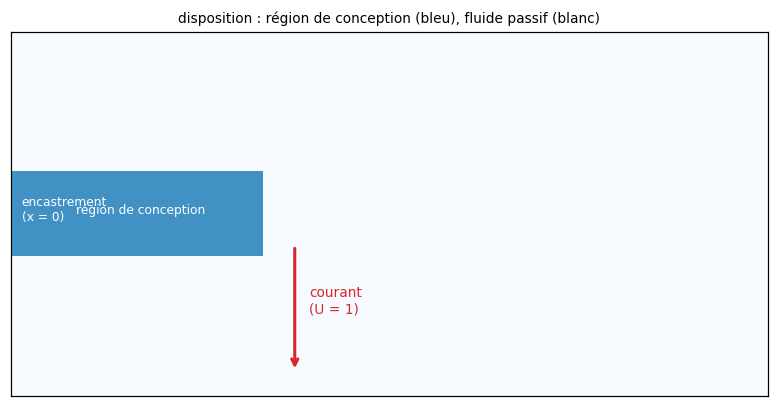

In [2]:
pb = probleme(0.5)
g = pb.grid
print(f"grille {g.shape}, {g.n_elems} éléments ; variables de conception : {pb.n_design} ; blocage = portée / largeur = {PORTEE/g.shape[0]:.2f}")
fig, ax = plt.subplots(figsize=(8, 3.8))
carte = np.zeros(g.shape); carte[pb.design_mask.numpy()] = 1
ax.imshow(carte.T[::-1], cmap="Blues", vmin=0, vmax=1.6, interpolation="nearest")
ax.annotate("", xy=(PORTEE + 4, g.shape[1] - 4), xytext=(PORTEE + 4, g.shape[1] - 22), arrowprops=dict(arrowstyle="->", color="C3", lw=2))
ax.text(PORTEE + 6, g.shape[1] - 14, "courant\n(U = 1)", color="C3", fontsize=9, va="center")
zc = g.shape[1] - 1 - (GEOM["pad_bottom"] + HAUTEUR // 2)
ax.text(1.0, zc, "encastrement\n(x = 0)", fontsize=8, color="w", va="center")
ax.text(PORTEE / 2, zc, "région de conception", fontsize=8, color="w", va="center", ha="center")
ax.set_title("disposition : région de conception (bleu), fluide passif (blanc)", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Normaliser : pourquoi, et le piège de la référence

$\mathcal C$ est une énergie (force $\times$ déplacement), $D$ une force : leurs valeurs numériques n'ont rien à voir, et une somme brute $\mathcal C+D$ n'aurait pas de sens (elle ne dépendrait que de l'unité choisie pour l'un des deux). On **divise chaque terme par une référence** : $\hat{\mathcal C}=\mathcal C/\mathcal C_{\rm ref}$, $\hat D=D/D_{\rm ref}$, tous deux sans dimension et de l'ordre de $1$ au point de référence. Les poids $w_c,w_a$ expriment alors une préférence : « combien de rigidité accepte-t-on de perdre pour un pour cent de téléchargement ? ».

**Les règles de `Composite`** (contrats C-OBJ-02, 03, 05) :
- les poids sont $\ge0$ et au moins un est $>0$ ;
- les références sont **figées une seule fois** : les changer en cours d'optimisation déplacerait l'optimum ;
- une référence doit être **strictement positive** : diviser par une référence négative retournerait le signe du terme, et l'optimiseur maximiserait $D$ au lieu de le minimiser ;
- `value()` renvoie $J$ **et** chaque terme brut et normalisé, pour pouvoir tracer le front après coup.

In [3]:
for poids in ({"C": 0.0, "D": 0.0}, {"C": -1.0, "D": 1.0}):
    try: Composite(poids)
    except ConfigError as e: print(f"poids {poids} -> ConfigError :", e)
c = Composite({"C": 0.5, "D": 0.5}, refs={"C": 10.0, "D": 4.0})
for tentative in (lambda: c.freeze_references({"C": torch.tensor(1.0), "D": torch.tensor(1.0)}), lambda: Composite({"C": 0.5, "D": 0.5}, refs={"C": 10.0, "D": -4.0})):
    try: tentative()
    except ConfigError as e: print("ConfigError :", e)
r = c.value({"C": torch.tensor(20.0), "D": torch.tensor(2.0), "vol": torch.tensor(0.4)}, [])
print("\ntermes rendus par value() :", {k: round(float(v), 3) for k, v in r.terms.items()}, "; J =", float(r.J))

poids {'C': 0.0, 'D': 0.0} -> ConfigError : at least one weight must be > 0, got {'C': 0.0, 'D': 0.0}
poids {'C': -1.0, 'D': 1.0} -> ConfigError : weights must be finite and >= 0, got {'C': -1.0, 'D': 1.0}
ConfigError : references are already frozen: changing them would move the optimum
ConfigError : reference for 'D' must be > 0 and finite, got -4

termes rendus par value() : {'C': 20.0, 'D': 2.0, 'vol': 0.4, 'C_hat': 2.0, 'D_hat': 0.5} ; J = 1.25


**Où prendre les références ?** Le plus naturel est la valeur au design initial. Mais le design initial est une densité **uniforme et floue** ($x=f_V$ partout, $\beta=1$) : aucun bord net, donc un $D$ qui n'a rien à voir avec celui d'une pièce. On le mesure, en optimisant d'abord la compliance seule ($w_a=0$) et en comparant :

In [4]:
t0 = time.time()
pb0 = probleme(0.0)
res0, sched = optimise(pb0, its=200)
x_C = res0.x                                                    # le design « compliance seule »
x_unif = pb0.initial_design()
t_init = termes(pb0, x_unif, beta=1.0)                           # le point de départ tel que l'optimiseur le voit (β = 1)
t_opt = termes(pb0, x_C)
print(f"optimisation de la compliance seule : {time.time()-t0:.1f} s, {len(res0.history)} itérations, arrêt : {res0.stop_reason}")
print(f"{'':>28} {'C':>9} {'D':>9}")
print(f"{'design uniforme (β = 1)':>28} {t_init['C']:>9.1f} {t_init['D']:>9.2f}")
print(f"{'design optimisé (β = 16)':>28} {t_opt['C']:>9.1f} {t_opt['D']:>9.2f}")
A0, _ = largeur_frontale(pb0, x_C)
print(f"\nlargeur frontale A du design optimisé : {A0:.1f} éléments = {A0/PORTEE:.2f} portées : le courant voit {A0/PORTEE:.1f} faces au vent par colonne (deux membrures)")
REFS = {"C": t_opt["C"], "D": t_opt["D"]}                        # références : design compliance convergé, indicateur protégé
print("références retenues :", {k: round(v, 2) for k, v in REFS.items()})

optimisation de la compliance seule : 8.4 s, 200 itérations, arrêt : max_iter
                                     C         D
     design uniforme (β = 1)    2376.4      8.45
    design optimisé (β = 16)     346.8     82.84

largeur frontale A du design optimisé : 67.9 éléments = 1.89 portées : le courant voit 1.9 faces au vent par colonne (deux membrures)
références retenues : {'C': 346.79, 'D': 82.84}


Les deux termes changent d'un facteur $7$ à $10$ entre le design de départ et le design optimisé, et **en sens opposés** : la compliance de départ est $6{,}9$ fois celle de l'optimum, tandis que $D$ est $9{,}8$ fois **plus petit** au départ (un champ flou, sans bord net, a très peu de surfaces au vent) qu'à l'optimum. Prendre le design de départ pour référence donnerait donc $\hat{\mathcal C}\approx0{,}15$ et $\hat D\approx9{,}8$ au design optimisé : des termes qui ne sont plus « de l'ordre de $1$ », et un poids $w_a$ dont le sens dépend de la phase de l'optimisation. **On fixe donc les références sur le design à compliance seule, convergé** : $\hat{\mathcal C}=1$ y est par définition, et $\hat D=1$ aussi. Un point à $(\hat{\mathcal C},\hat D)=(1,1)$ sert alors d'origine au front, et les autres designs se lisent comme « $\hat{\mathcal C}$ fois plus de compliance, $\hat D$ fois le téléchargement » par rapport à lui.

**Ce que fait la valeur $A/$portée.** La largeur frontale $A$ du notebook 15 compte **toutes** les faces au vent rencontrées sur une verticale : la console optimisée en a deux par colonne (les deux membrures, dessus et dessous) et le courant frappe la membrure du bas à travers celle du haut. C'est l'enjeu du compromis.

## 3. Quand l'optimiseur triche

Le notebook 15 a montré que $D$ est un **indicateur**, pas une force. Un indicateur biaisé est dangereux dès qu'on **l'optimise** : l'optimiseur cherche les endroits où il se trompe dans le bon sens. On le vérifie avec un poids fort sur $D$ ($w_a=0{,}9$), en partant du design à compliance seule, sous quatre versions de l'indicateur :

| | pression | plancher |
|---|---|---|
| (a) | brute (champ éléments finis) | non |
| (b) | côté fluide, $\rho_c=1$, $\varepsilon\approx0$ (version du notebook 15) | non |
| (c) | côté fluide, cellules $\bar\rho\ge0{,}5$ sans poids, $\varepsilon=10^{-2}$ | non |
| (d) | comme (c) | **oui** : pression au vent $\ge$ pression de culot |

Chaque version a **sa propre référence** (son $D$ au design à compliance seule). Pour comparer les designs sur un pied d'égalité, on les **réévalue tous avec l'indicateur (d)**, le plus protégé (colonne « $\hat D$ audité »).

indicateur utilisé                 Ĉ D̂ propre D̂ audité (d)  A/portée
(a) brute                    refusé par Composite : reference for 'D' must be > 0 and finite, got -9654


(a) brute                      19.99     -8.91          0.69      1.54


(b) côté fluide (nb 15)        11.15    -32.22          0.49      1.20


(c) + ρ_c = 0,5, ε = 1e-2       9.32     -0.29          0.44      1.06


(d) + plancher                  3.50      0.25          0.25      1.17
(35 s)


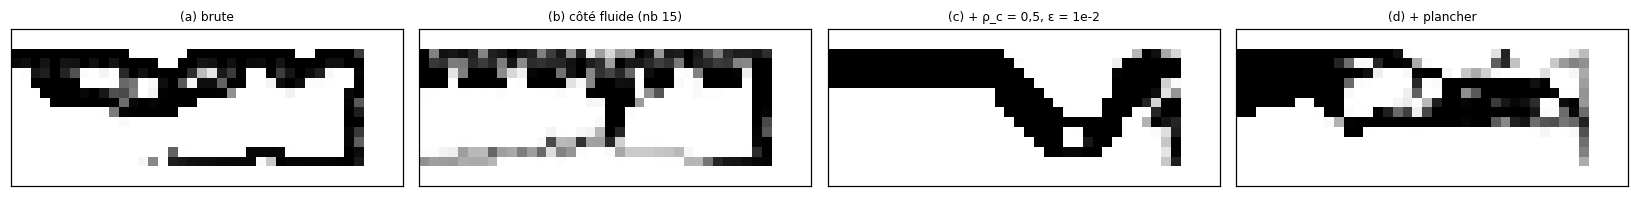

In [5]:
VARIANTES = {
    "(a) brute": dict(fluid_side=False, floor_at_base=False),
    "(b) côté fluide (nb 15)": dict(fluid_side=True, floor_at_base=False, pressure_kw=dict(rho_c=1.0, eps=1e-12)),
    "(c) + ρ_c = 0,5, ε = 1e-2": dict(fluid_side=True, floor_at_base=False),
    "(d) + plancher": dict(fluid_side=True, floor_at_base=True),
}
audit = probleme(0.5, **VARIANTES["(d) + plancher"])
t_ref_d = termes(audit, x_C)
audit = probleme(0.5, refs={"C": t_ref_d["C"], "D": t_ref_d["D"]}, **VARIANTES["(d) + plancher"])
designs3 = {}
print(f"{'indicateur utilisé':<28} {'Ĉ':>7} {'D̂ propre':>9} {'D̂ audité (d)':>13} {'A/portée':>9}")
t0 = time.time()
for nom, kw in VARIANTES.items():
    ref_v = termes(probleme(0.5, **kw), x_C)                      # D au design compliance seule, sous CET indicateur
    try:
        pbv = probleme(0.9, refs={"C": ref_v["C"], "D": ref_v["D"]}, **kw)
    except ConfigError as e:                                      # le garde-fou de Composite : D_ref ≤ 0
        print(f"{nom:<28} refusé par Composite : {e}")
        ref_v["D"] = abs(ref_v["D"])                              # on force |D_ref| pour VOIR ce que ferait l'optimiseur
        pbv = probleme(0.9, refs={"C": ref_v["C"], "D": ref_v["D"]}, **kw)
    r, _ = optimise(pbv, x0=x_C, beta=(4.0, 16.0), its=200)
    tv = termes(pbv, r.x); ta = termes(audit, r.x); A, _ = largeur_frontale(pbv, r.x)
    designs3[nom] = (pbv, r.x)
    print(f"{nom:<28} {tv['C']/ref_v['C']:>7.2f} {tv['D']/ref_v['D']:>9.2f} {ta['D']/t_ref_d['D']:>13.2f} {A/PORTEE:>9.2f}")
print(f"({time.time()-t0:.0f} s)")
fig, axs = plt.subplots(1, 4, figsize=(15, 2.6))
for ax, (nom, (pbv, xv)) in zip(axs, designs3.items()): montre(ax, pbv, xv, nom)
plt.tight_layout(); plt.show()

**Lecture.**
- **(a) Pression brute.** `Composite` **refuse** d'emblée la référence : $D$ au design à compliance seule vaut $-9654$ avec la pression brute (aspiration infinie aux arêtes vives du potentiel), et diviser par une référence négative retournerait le sens de l'optimisation. C'est exactement le garde-fou voulu. Pour *voir* ce que ferait l'optimiseur, on force la valeur absolue : il atteint $\hat D=-8{,}9$ (un « téléchargement négatif » qui n'a aucun sens physique) en payant $20$ fois la compliance ; réévalué avec l'indicateur protégé, son $\hat D$ n'est que de $0{,}69$.
- **(b) Côté fluide, version du notebook 15.** Même histoire : $\hat D=-32$ pour le critère propre, $11$ fois la compliance, et $0{,}49$ à l'audit.
- **(c) Poids nuls au-dessus de $\bar\rho=0{,}5$ et $\varepsilon$.** Le critère propre reste **négatif** ($-0{,}29$) : l'ajustement des poids élimine l'essentiel de la triche, pas toute. Compliance $\times9{,}3$, audit $0{,}44$.
- **(d) Avec le plancher de culot.** $\hat D=0{,}25$ au critère propre comme à l'audit (c'est le même indicateur), pour une compliance $\times3{,}5$ seulement.

**La protection n'est pas cosmétique.** Les trois premières versions dépensent $9$ à $20$ fois la compliance pour poursuivre un $D$ négatif qui n'existe que dans le modèle, et le design obtenu est **moins bon** que celui de (d) même jugé avec l'indicateur de (d). Deux réserves : l'audit utilise l'indicateur (d), choisi par nous, ce n'est pas une vérité de terrain ; et la protection fait ce que dit sa définition ($D$ minoré par $0$), ce qui ne prouve pas que $D$ est juste. Le notebook 15 a montré que sa valeur absolue dépend de $c_b$ ; le §6 mesure ce que cela change au design.

## 4. Le front de Pareto

On fait varier $w_a$ de $0$ à $1$ (avec $w_c=1-w_a$) et on garde, pour chaque poids, la compliance et le téléchargement **bruts normalisés**. Chaque point est un design optimal pour un compromis donné ; l'ensemble des points qui ne sont **dominés** par aucun autre (aucun autre design n'est meilleur sur les deux critères à la fois) est le **front de Pareto**.

Deux précautions : (i) l'optimisation est non convexe, donc chaque point est un **minimum local**, et le front obtenu est celui des minima trouvés, pas le vrai front ; pour limiter le bruit on balaie **deux fois**, en montant puis en descendant en $w_a$, chaque calcul repartant du design précédent, et on garde l'union ; (ii) une **somme pondérée** ne peut atteindre que la partie *convexe* du front : les compromis situés dans un creux du front ne sont retrouvés pour aucun poids.

In [6]:
WA = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.97]
points = []                                                       # (wa, passe, C_hat, D_hat, vol, A/portée, x)
t0 = time.time(); x = x_C
for passe, ordre in (("montante", WA), ("descendante", WA[::-1])):   # la descendante repart du dernier design de la montante
    for wa in ordre:
        pbw = probleme(wa, refs=REFS)
        r, _ = optimise(pbw, x0=x, beta=(4.0, 16.0), its=200)
        x = r.x; t = termes(pbw, x); A, _ = largeur_frontale(pbw, x)
        points.append((wa, passe, t["C"] / REFS["C"], t["D"] / REFS["D"], t["vol"], A / PORTEE, x.copy()))
print(f"{len(points)} optimisations, {time.time()-t0:.0f} s")
C_, D_ = np.array([p[2] for p in points]), np.array([p[3] for p in points])
domine = np.array([any((C_[j] <= C_[i]) and (D_[j] <= D_[i]) and ((C_[j] < C_[i]) or (D_[j] < D_[i])) for j in range(len(points))) for i in range(len(points))])
print(f"{'w_a':>5} {'passe':>12} {'Ĉ':>7} {'D̂':>7} {'volume':>7} {'A/portée':>9}  dominé ?")
for i in np.argsort([p[0] for p in points], kind="stable"):
    p = points[i]; print(f"{p[0]:>5.2f} {p[1]:>12} {p[2]:>7.2f} {p[3]:>7.2f} {p[4]:>7.3f} {p[5]:>9.2f}  {'oui' if domine[i] else ''}")

18 optimisations, 151 s
  w_a        passe       Ĉ      D̂  volume  A/portée  dominé ?
 0.00     montante    0.85    0.98   0.400      1.86  
 0.00  descendante    1.23    0.81   0.400      1.74  oui
 0.05     montante    4.58    0.50   0.400      1.17  oui
 0.05  descendante    3.40    0.49   0.400      1.22  oui
 0.10     montante    4.91    0.56   0.400      1.24  oui
 0.10  descendante    4.96    0.35   0.400      1.00  oui
 0.20     montante    1.19    0.72   0.400      1.59  
 0.20  descendante    4.11    0.48   0.400      1.14  oui
 0.30     montante    0.95    0.74   0.400      1.58  
 0.30  descendante    1.28    0.69   0.400      1.59  
 0.50     montante    3.65    0.34   0.400      1.12  oui
 0.50  descendante    4.27    0.35   0.400      1.03  oui
 0.70     montante    5.16    0.33   0.400      1.09  oui
 0.70  descendante    1.49    0.43   0.400      1.17  
 0.90     montante    5.16    0.30   0.400      1.00  oui
 0.90  descendante    3.21    0.32   0.400      1.00  
 0.

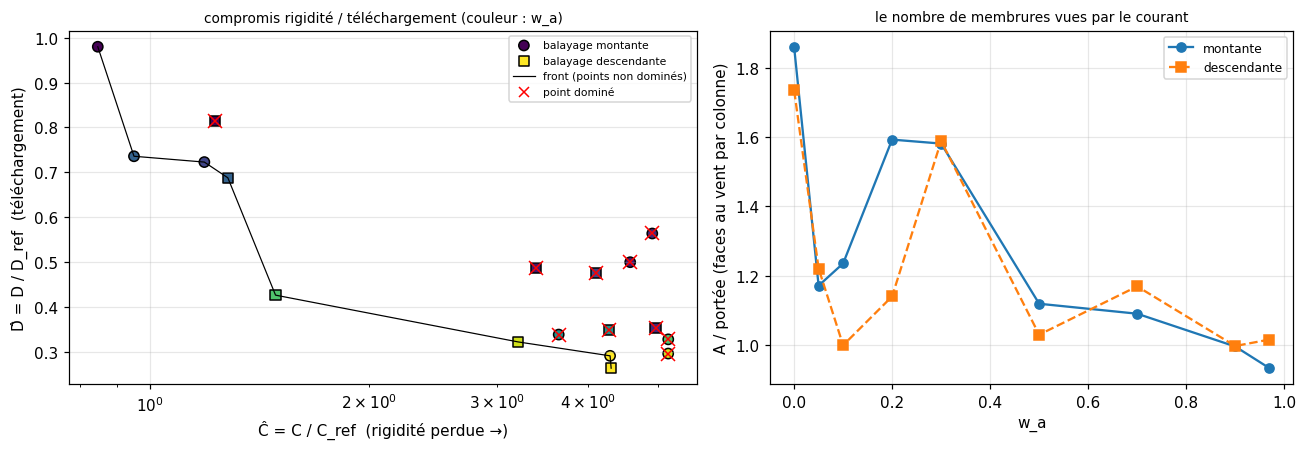

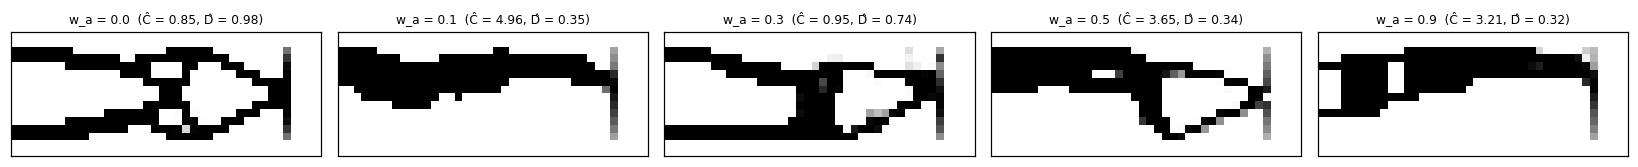

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
for passe, mk in (("montante", "o"), ("descendante", "s")):
    idx = [i for i, p in enumerate(points) if p[1] == passe]
    ax[0].scatter(C_[idx], D_[idx], marker=mk, c=[points[i][0] for i in idx], cmap="viridis", s=45, edgecolor="k", label=f"balayage {passe}")
for i in np.where(domine)[0]: ax[0].plot(C_[i], D_[i], "rx", ms=9)
nd = np.where(~domine)[0]; nd = nd[np.argsort(C_[nd])]
ax[0].plot(C_[nd], D_[nd], "k-", lw=0.8, label="front (points non dominés)")
ax[0].plot([], [], "rx", label="point dominé")
ax[0].set_xscale("log"); ax[0].set_xlabel("Ĉ = C / C_ref  (rigidité perdue →)"); ax[0].set_ylabel("D̂ = D / D_ref  (téléchargement)"); ax[0].legend(fontsize=7)
ax[0].set_title("compromis rigidité / téléchargement (couleur : w_a)", fontsize=9); ax[0].grid(alpha=0.3)
ax[1].plot([p[0] for p in points if p[1] == 'montante'], [p[5] for p in points if p[1] == 'montante'], "o-", label="montante")
ax[1].plot([p[0] for p in points if p[1] == 'descendante'], [p[5] for p in points if p[1] == 'descendante'], "s--", label="descendante")
ax[1].set_xlabel("w_a"); ax[1].set_ylabel("A / portée (faces au vent par colonne)"); ax[1].legend(fontsize=8); ax[1].set_title("le nombre de membrures vues par le courant", fontsize=9); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
choix = [0.0, 0.1, 0.3, 0.5, 0.9]
fig, axs = plt.subplots(1, len(choix), figsize=(3 * len(choix), 2.6))
for ax_, wa in zip(axs, choix):
    i = min([i for i, p in enumerate(points) if p[0] == wa], key=lambda i: C_[i] + D_[i])
    montre(ax_, probleme(wa, refs=REFS), points[i][6], f"w_a = {wa}  (Ĉ = {C_[i]:.2f}, D̂ = {D_[i]:.2f})")
plt.tight_layout(); plt.show()

**Lecture.**
- **Le front est bruité.** 18 optimisations, dont **8 seulement sont non dominées**. Pour un même poids, les deux balayages donnent parfois des designs très différents : $w_a=0{,}7$ donne $(\hat{\mathcal C},\hat D)=(5{,}2;\,0{,}33)$ en montant et $(1{,}5;\,0{,}43)$ en descendant ; $w_a=0{,}9$ donne $(5{,}2;\,0{,}30)$ et $(3{,}2;\,0{,}32)$. Chaque point est un minimum local, et un balayage unique aurait donné une courbe fausse. L'incertitude sur $\hat D$ due au bruit de la force numérique (notebook 15, $\sim0{,}1\,qA$) est de l'ordre de $0{,}05$ ici : les écarts de $\hat D$ plus petits que cela ne signifient rien.
- **Les points non dominés dessinent trois régimes.** (i) $(\hat{\mathcal C},\hat D)=(0{,}85;\,0{,}98)\to(0{,}95;\,0{,}74)$ : gagner $25\,\%$ sur $D$ pour $12\,\%$ de compliance en plus, avec **deux membrures** conservées ($A/\text{portée}\approx1{,}6$, la membrure basse se rapproche de l'autre) ; (ii) $(1{,}5;\,0{,}43)$ : $-56\,\%$ de $D$ pour $\hat{\mathcal C}=1{,}5$ ; (iii) $(3{,}2\text{ à }4{,}3;\,0{,}26\text{ à }0{,}32)$ : $-70\,\%$ de $D$ pour **trois à quatre fois** la compliance de référence, avec **une seule membrure** ($A/\text{portée}\approx1{,}0$).
- **Le mécanisme est visible sur les vignettes.** Le design à compliance seule a deux membrures (haut et bas) reliées par un treillis, et le courant frappe les deux faces au vent ($A=1{,}9$ portées). Sous un poids fort sur $D$, la membrure du bas disparaît : il ne reste qu'une plaque (poutre en I sans l'âme ni la semelle basse), de rigidité bien moindre. Le courant ne voit plus qu'une face au vent par colonne.
- **Ce que le front ne dit pas.** Il est calculé avec un $c_b$ et une pression côté fluide dont la validité n'est pas établie (notebook 15). Une somme pondérée ne retrouve de plus que la partie convexe du front ; rien ici ne dit s'il existe des compromis dans un creux. Et $\hat{\mathcal C}<1$ au point $w_a=0$ vient de ce que la référence est celle d'un départ à froid, qui est un moins bon minimum que celui d'un départ à chaud.

## 5. Le gradient du coût composite, et le prix d'une évaluation

Le coût $J$ dépend de $x$ par une longue chaîne : filtre, projection, puis **deux** résolutions éléments finis (structure et écoulement), l'indicateur $D$ avec sa pression côté fluide, la normalisation, la somme pondérée. Aucune dérivée n'est écrite à la main sauf l'état adjoint (une seule `Function`, notebook 7), appliqué ici à deux systèmes. On vérifie le résultat final contre des **différences finies centrées**, dans trois directions aléatoires et pour $w_a\in\{0,\frac12,1\}$ (contrat C-OBJ-06) :

In [8]:
gen = torch.Generator().manual_seed(11)
x_test = (0.25 + 0.5 * torch.rand(PORTEE * HAUTEUR, generator=gen))
print(f"{'w_a':>5} {'direction':>10} {'dJ autograd':>13} {'dJ diff. finies':>16} {'écart relatif':>14}")
for wa in (0.0, 0.5, 1.0):
    pbg = probleme(wa, refs=REFS); pbg.set_continuation({"p": 3.0, "beta": 2.0})
    x = x_test.clone().requires_grad_(True)
    (gr,) = torch.autograd.grad(pbg.evaluate(x).J, x)
    for k in range(3):
        d = torch.randn(x.numel(), generator=gen); d /= d.norm(); h = 1e-6
        fd = (float(pbg.evaluate(x_test + h * d).J) - float(pbg.evaluate(x_test - h * d).J)) / (2 * h)
        print(f"{wa:>5.1f} {k:>10d} {float(gr @ d):>13.6e} {fd:>16.6e} {abs(float(gr @ d) - fd) / abs(fd):>14.1e}")

  w_a  direction   dJ autograd  dJ diff. finies  écart relatif
  0.0          0 -7.417194e-02    -7.417201e-02        8.6e-07


  0.0          1  7.207860e-03     7.207160e-03        9.7e-05
  0.0          2 -5.653955e-02    -5.653968e-02        2.3e-06


  0.5          0 -6.852807e-02    -6.852806e-02        8.1e-08
  0.5          1  1.173245e-01     1.173246e-01        5.3e-07
  0.5          2 -7.428750e-03    -7.428927e-03        2.4e-05


  1.0          0 -6.738270e-03    -6.738269e-03        1.6e-07
  1.0          1 -5.460143e-03    -5.460143e-03        4.9e-08
  1.0          2  3.580182e-04     3.580184e-04        6.4e-07


In [9]:
class Compteur:
    # solveur direct qui compte les factorisations (prepare) et les résolutions
    def __init__(self): self.inner, self.prepare_n, self.solve_n = ScipyDirect(), 0, 0
    def prepare(self, op, w):
        self.prepare_n += 1; h = self.inner.prepare(op, w); me = self
        class H:
            def solve(self, b): me.solve_n += 1; return h.solve(b)
        return H()

meca, flux = Compteur(), Compteur()
pbc = probleme(0.5, refs=REFS, solver=meca, flow_solver=flux)
x = torch.as_tensor(x_C).clone().requires_grad_(True)
t = time.perf_counter(); res = pbc.evaluate(x); t_fwd = time.perf_counter() - t
n_fwd = (meca.prepare_n, meca.solve_n, flux.prepare_n, flux.solve_n)
t = time.perf_counter(); torch.autograd.grad(res.J, x); t_bwd = time.perf_counter() - t
print(f"évaluation (avant)   : {1e3*t_fwd:.0f} ms ; structure : {n_fwd[0]} factorisation, {n_fwd[1]} résolution ; écoulement : {n_fwd[2]} factorisation, {n_fwd[3]} résolution")
print(f"gradient (arrière)   : {1e3*t_bwd:.0f} ms ; résolutions de plus : structure {meca.solve_n-n_fwd[1]}, écoulement {flux.solve_n-n_fwd[3]} ; factorisations de plus : {meca.prepare_n-n_fwd[0]} et {flux.prepare_n-n_fwd[2]}")
print(f"grille {pbc.grid.shape} ({pbc.grid.n_elems} éléments), {pbc.n_design} variables")

évaluation (avant)   : 54 ms ; structure : 1 factorisation, 1 résolution ; écoulement : 1 factorisation, 1 résolution
gradient (arrière)   : 3 ms ; résolutions de plus : structure 1, écoulement 1 ; factorisations de plus : 0 et 0
grille (108, 52) (5616 éléments), 432 variables


**Lecture.**
- **Les écarts sont à la précision des différences finies** : de $5\times10^{-8}$ à $10^{-4}$ en relatif, le plus grand ($10^{-4}$) sur une direction où la dérivée est petite ($7\times10^{-3}$, donc plus sensible au bruit d'arrondi du quotient). Le gradient passe par les deux adjoints, le filtre, la projection et la pression côté fluide.
- **Une évaluation fait une factorisation et une résolution par système**, et le gradient ne coûte **qu'une résolution de plus par système, sans nouvelle factorisation** (le gradient de $J$ pour $432$ variables : $3\,$ms, contre $54\,$ms pour l'évaluation, qui contient les deux factorisations ; la répartition n'a pas été mesurée plus finement). C'est ce qu'achète l'état adjoint (C-OBJ-01) : le coût ne dépend pas du nombre de variables. Ce chiffre vaut pour ce petit cas 2D et un solveur direct ; en 3D, c'est le gradient conjugué et le multigrille des notebooks 5 et 6 qui prendront le relais.

## 6. Sensibilité à $c_b$

Le coefficient de culot $c_b$ n'est calibré par rien dans ce projet (notebook 15). Change-t-il le design optimal ? On refait l'optimisation à $w_a=0{,}9$ pour trois valeurs, chacune avec sa propre référence (le $D$ du design à compliance seule sous ce $c_b$), et on réévalue sous le $c_b$ de référence $1{,}4$.

  c_b       Ĉ  D̂ (propre)  A/portée  D̂ audité à c_b = 1,4


  0.4    2.10         0.24      1.16                   0.36


  1.4    3.50         0.25      1.17                   0.25


  3.0    3.86         0.36      0.98                   0.32


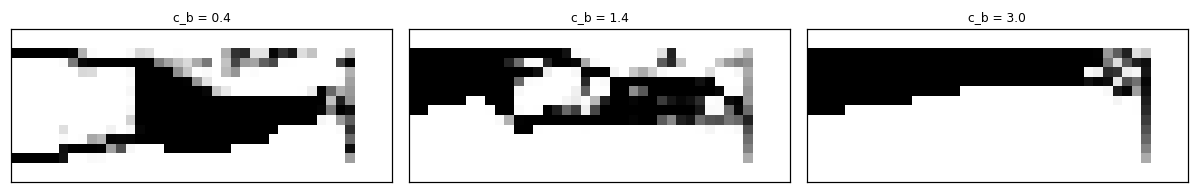

In [10]:
print(f"{'c_b':>5} {'Ĉ':>7} {'D̂ (propre)':>12} {'A/portée':>9} {'D̂ audité à c_b = 1,4':>22}")
dess6 = []
for cb in (0.4, 1.4, 3.0):
    ref_c = termes(probleme(0.5, c_b=cb), x_C)
    pbc_ = probleme(0.9, refs={"C": ref_c["C"], "D": ref_c["D"]}, c_b=cb)
    r, _ = optimise(pbc_, x0=x_C, beta=(4.0, 16.0), its=200)
    tc = termes(pbc_, r.x); A, _ = largeur_frontale(pbc_, r.x); ta = termes(audit, r.x)
    dess6.append((cb, pbc_, r.x))
    print(f"{cb:>5.1f} {tc['C']/ref_c['C']:>7.2f} {tc['D']/ref_c['D']:>12.2f} {A/PORTEE:>9.2f} {ta['D']/t_ref_d['D']:>22.2f}")
fig, axs = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, (cb, pbc_, xc) in zip(axs, dess6): montre(ax, pbc_, xc, f"c_b = {cb}")
plt.tight_layout(); plt.show()

**Lecture.**
- La **topologie** ne change pas : les trois designs n'ont qu'une membrure ($A/\text{portée}=1{,}16$, $1{,}17$ et $0{,}98$). La **valeur** du compromis change beaucoup : à $c_b=0{,}4$ la compliance est multipliée par $2{,}1$, à $c_b=1{,}4$ par $3{,}5$, à $c_b=3$ par $3{,}9$ : plus $c_b$ est grand, plus l'optimiseur sacrifie de rigidité. L'explication plausible est que la part de $D$ proportionnelle à la largeur frontale ($c_b\,qA$) domine alors ; elle n'a pas été isolée.
- À l'audit sous $c_b=1{,}4$, le design optimisé pour $c_b=1{,}4$ est le meilleur ($0{,}25$ contre $0{,}36$ et $0{,}32$) ; c'est le résultat attendu, et il ne dit rien sur lequel est le bon $c_b$.
- **Conséquence pratique** : le projet peut affirmer qu'un poids fort sur $D$ supprime une membrure (robuste au $c_b$), mais **pas** combien de rigidité il faut payer : ce chiffre dépend d'un coefficient que rien ne calibre. Une soufflerie ou une CFD sur deux designs (avec et sans la membrure basse) fixerait $c_b$ bien mieux que tout ce qui précède.

## 7. Bilan

| Constat | Où c'est dans le code |
|---|---|
| Deux physiques, une densité : une résolution de chaque, deux adjoints, $J$ et $g_V$ ; $3\,$ms de gradient pour $54\,$ms d'évaluation | `CoupledProblem`, C-OBJ-01 |
| Les poids sont validés, les références figées une fois et strictement positives ; tous les termes (bruts et normalisés) sont rendus | `Composite`, C-OBJ-02, 03, 05 |
| La référence se prend sur un design **convergé** : au design uniforme, $\mathcal C$ est $6{,}9\times$ trop haute et $D$ $9{,}8\times$ trop bas | §2, C-OBJ-03 |
| Le volume se compte sur $\mathcal D\cup\mathcal S$ seulement | `volume_constraint`, C-OBJ-04 |
| Le gradient du coût composite est exact aux différences finies près | §5, C-OBJ-06 |
| **$D$ non protégé est exploité** par l'optimiseur : $\hat D$ jusqu'à $-32$ pour $9$ à $20\times$ la compliance, et des designs moins bons à l'audit | §3, C-AERO-07 |
| Avec le plancher de culot, $D\ge0$ ; même design jugé à l'audit : $0{,}25$ pour $3{,}5\times$ la compliance | §3, `floor_at_base` |
| Front de Pareto : bruité (8 points non dominés sur 18) ; une membrure en moins : $\hat{\mathcal C}$ de $3{,}2$ à $4{,}3$ pour $-70\,\%$ de $D$ | §4, C-OBJ-07 |
| Le $c_b$ change le prix du compromis ($\times2{,}1$ à $\times3{,}9$), pas sa nature | §6 |

**Limites à retenir.**
- **Le sens physique de $D$ est le maillon faible** (notebook 15) : $c_b$ est non calibré, l'indicateur ne voit pas la forme de l'arrière, la pression d'interface est un pansement. Tout le front en dépend.
- **Les protections ajoutées** (poids nuls au-dessus de $\bar\rho=0{,}5$, $\varepsilon$, plancher de culot) ont été choisies ici d'après un seul cas ; elles ne sont **pas** dans le FORMALISM. À valider avant de les adopter.
- **Un cas 2D, vue de côté.** Le fluide voit une tranche infinie dans l'épaisseur, la console est un bras « large » ; un vrai bras de drone est mieux décrit par sa section droite (un problème 2D différent) ou par un calcul 3D, que ce code ne fait pas encore tourner de bout en bout.
- **La charge répartie reste accrochée aux nœuds du bord**, même sans matière (notebook 13) : l'optimiseur doit donc garder de la matière en bout de console, ce qu'on voit sur les designs (la bande verticale à droite).
- **Les autres briques ne sont pas branchées ici** : filtre de surplomb (notebook 12), orthotropie (notebook 11), sortie imprimable (notebook 13). `ComplianceProblem` les accepte ; `CoupledProblem` accepte l'orthotropie (`C0`, non testée ici) mais pas encore le surplomb. Leur combinaison avec le fluide n'a **pas été testée**.
- **Les minima locaux** : un seul départ par point, deux balayages ; aucune garantie d'optimum global.
- **Ce qui manque pour la v1** : `Problem.from_config` et la lecture de la configuration, `io/results` (traçabilité de $c_b$, $\kappa$, $k_w$ : C-AERO-06), le 3D à l'échelle (phase 6), et surtout une calibration de $c_b$ sur des mesures.

**Pour expérimenter.** (i) Au §4, refaites le balayage avec un départ différent (par exemple le design à un seul membre) : retrouve-t-on les mêmes points non dominés ? (ii) Au §3, ajoutez une quatrième variante : $c_b=3$ avec la pression brute et le plancher (le plancher seul suffit-il ?). (iii) Au §6, faites varier la marge latérale (blocage) : le nombre de membrures du design change-t-il ? (iv) Ajoutez `OverhangParams` à `CoupledProblem` : l'auto-support est-il compatible avec la suppression de la membrure basse ?

*Fin du cours. Retour au [plan des leçons](README.md).*